In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import gspread 
from google.oauth2.service_account import Credentials
import matplotlib.dates as mdates

In [2]:
# Google auth
scope = [
    "https://www.googleapis.com/auth/spreadsheets",
    "https://www.googleapis.com/auth/drive"
]

creds = Credentials.from_service_account_file(
    "/workspaces/steel_stock_management/credentials.json",
    scopes=scope
)

gc = gspread.authorize(creds)

sheet = gc.open_by_url("https://docs.google.com/spreadsheets/d/1qAsFjW2lT8e54FsvsMkfGIHwQEDxsQuf4SzVAMXlK-g/edit?gid=824196706#gid=824196706")


In [3]:
inventory_ws = sheet.worksheet('inventario')
mat_dict_ws = sheet.worksheet('mat_dict')
pedidos_proveedores = sheet.worksheet('pedidos_proveedores') 

In [4]:
inventory_df = pd.DataFrame(inventory_ws.get_all_records())
materials_df = pd.DataFrame(mat_dict_ws.get_all_records())
suppliers_df = pd.DataFrame(pedidos_proveedores.get_all_records())

In [5]:
# Raw data and preprocessing
df_raw = inventory_df.copy()

df_baking = df_raw.copy()

# Convert dates from columns back into rows
df_baking = df_baking.melt(
    id_vars="material",
    var_name="fecha",
    value_name="inventario"
)

# Preprocessing
df_baking['fecha'] = pd.to_datetime(df_baking['fecha'])
df_baking["material"] = df_baking["material"].astype("category")

df_baking = df_baking.set_index('fecha')

df = df_baking.copy()

df.head()

,material,inventario
fecha,,
2026-05-19,ARMEX DE 15 x 15,551.00
2026-05-19,ARMEX DE 15 x 20,9.00
2026-05-19,"VARILLA CORRUGADA 3/8""",1148.00
2026-05-19,"VARILLA CORRUGADA 1/2""",511.00
2026-05-19,ALAMBRE RECOCIDO,1924.63


In [7]:
df.to_csv('/workspaces/steel_stock_management/data/inventory_df.csv', index=True)
materials_df.to_csv('/workspaces/steel_stock_management/data/mat_dict.csv', index=False)
suppliers_df.to_csv('/workspaces/steel_stock_management/data/pedidos_proveedores.csv', index=False)

In [17]:
# Material dict
mat_dict = materials_df.set_index("material").to_dict(orient="index")

In [18]:
def choose_annotation_position(ax, x_point, y_point):
    x_min, x_max = ax.get_xlim()
    y_min, y_max = ax.get_ylim()

    x_num = mdates.date2num(pd.to_datetime(x_point))

    x_mid = (x_min + x_max) / 2
    y_mid = (y_min + y_max) / 2

    if y_point > y_mid:
        y_offset = -35
        va = "top"
    else:
        y_offset = 35
        va = "bottom"

    if x_num > x_mid:
        x_offset = -35
        ha = "right"
    else:
        x_offset = 35
        ha = "left"

    return (x_offset, y_offset), ha, va

In [19]:
sns.set_theme(style="whitegrid", palette="deep")

def display_graphics(ax, material, purchase_date, received, quantity, unit, minimum_stock):

    mat = df[df["material"] == material].copy()

    mat = mat.reset_index()

    sns.lineplot(
        data=mat,
        x='fecha',
        y="inventario",
        linewidth=2.5,
        ax=ax
    )
    
    ax.set_title(material.upper())
    ax.set_xlabel("Día")
    ax.set_ylabel("Inventario")
    ax.tick_params(axis='x', rotation=45)

    ax.axhline(
        minimum_stock,
        color="red",
        linestyle="--",
        linewidth=2,
        label="Mínimo"
    )

    ax.axvline(
        pd.to_datetime(received),
        color="green",
        linestyle="--",
        linewidth=2,
        label="Recibido"
    )

    ax.axvline(
        pd.to_datetime(purchase_date),
        color="black",
        linestyle="--",
        linewidth=2,
        label="Pedido"
    )

    purchase_dt = pd.to_datetime(purchase_date)
    received_dt = pd.to_datetime(received)

    mat = mat.reset_index()  # brings fecha back as a column
    mat["fecha"] = pd.to_datetime(mat["fecha"])

    closest_idx = (mat["fecha"] - purchase_dt).abs().idxmin()
    closest_inventory = mat.loc[closest_idx, "inventario"]

    y_min, y_max = ax.get_ylim()
    y_range = y_max - y_min

    # Keep the label inside the graph
    text_y = min(closest_inventory + 0.08 * y_range, y_max - 0.08 * y_range)

    offset, ha, va = choose_annotation_position(
        ax,
        received_dt,
        closest_inventory
    )

    ax.annotate(
        f"{quantity} {unit}",
        xy=(received_dt, closest_inventory),
        xytext=offset,
        textcoords="offset points",
        ha=ha,
        va=va,
        arrowprops=dict(
            arrowstyle="->",
            lw=1.5,
            shrinkA=2,
            shrinkB=2,
            color='black'
        ),
        fontsize=8,
        bbox=dict(
            boxstyle="round,pad=0.2",
            fc="white",
            alpha=0.85
        ),
        clip_on=True
    )

    mat = mat.copy()
    mat["daily_change"] = mat["inventario"].diff()
    consumption = -mat["daily_change"]
    consumption = consumption[consumption > 0]
    avg = consumption.mean()

    ax.text(
        0.02, 0.95,
        f"Consumo:\n{avg:.1f}/{unit}/Día",
        transform=ax.transAxes,
        fontsize=9,
        va="top",
        bbox=dict(boxstyle="round", facecolor="white")
    )

    ax.legend(fontsize=8)

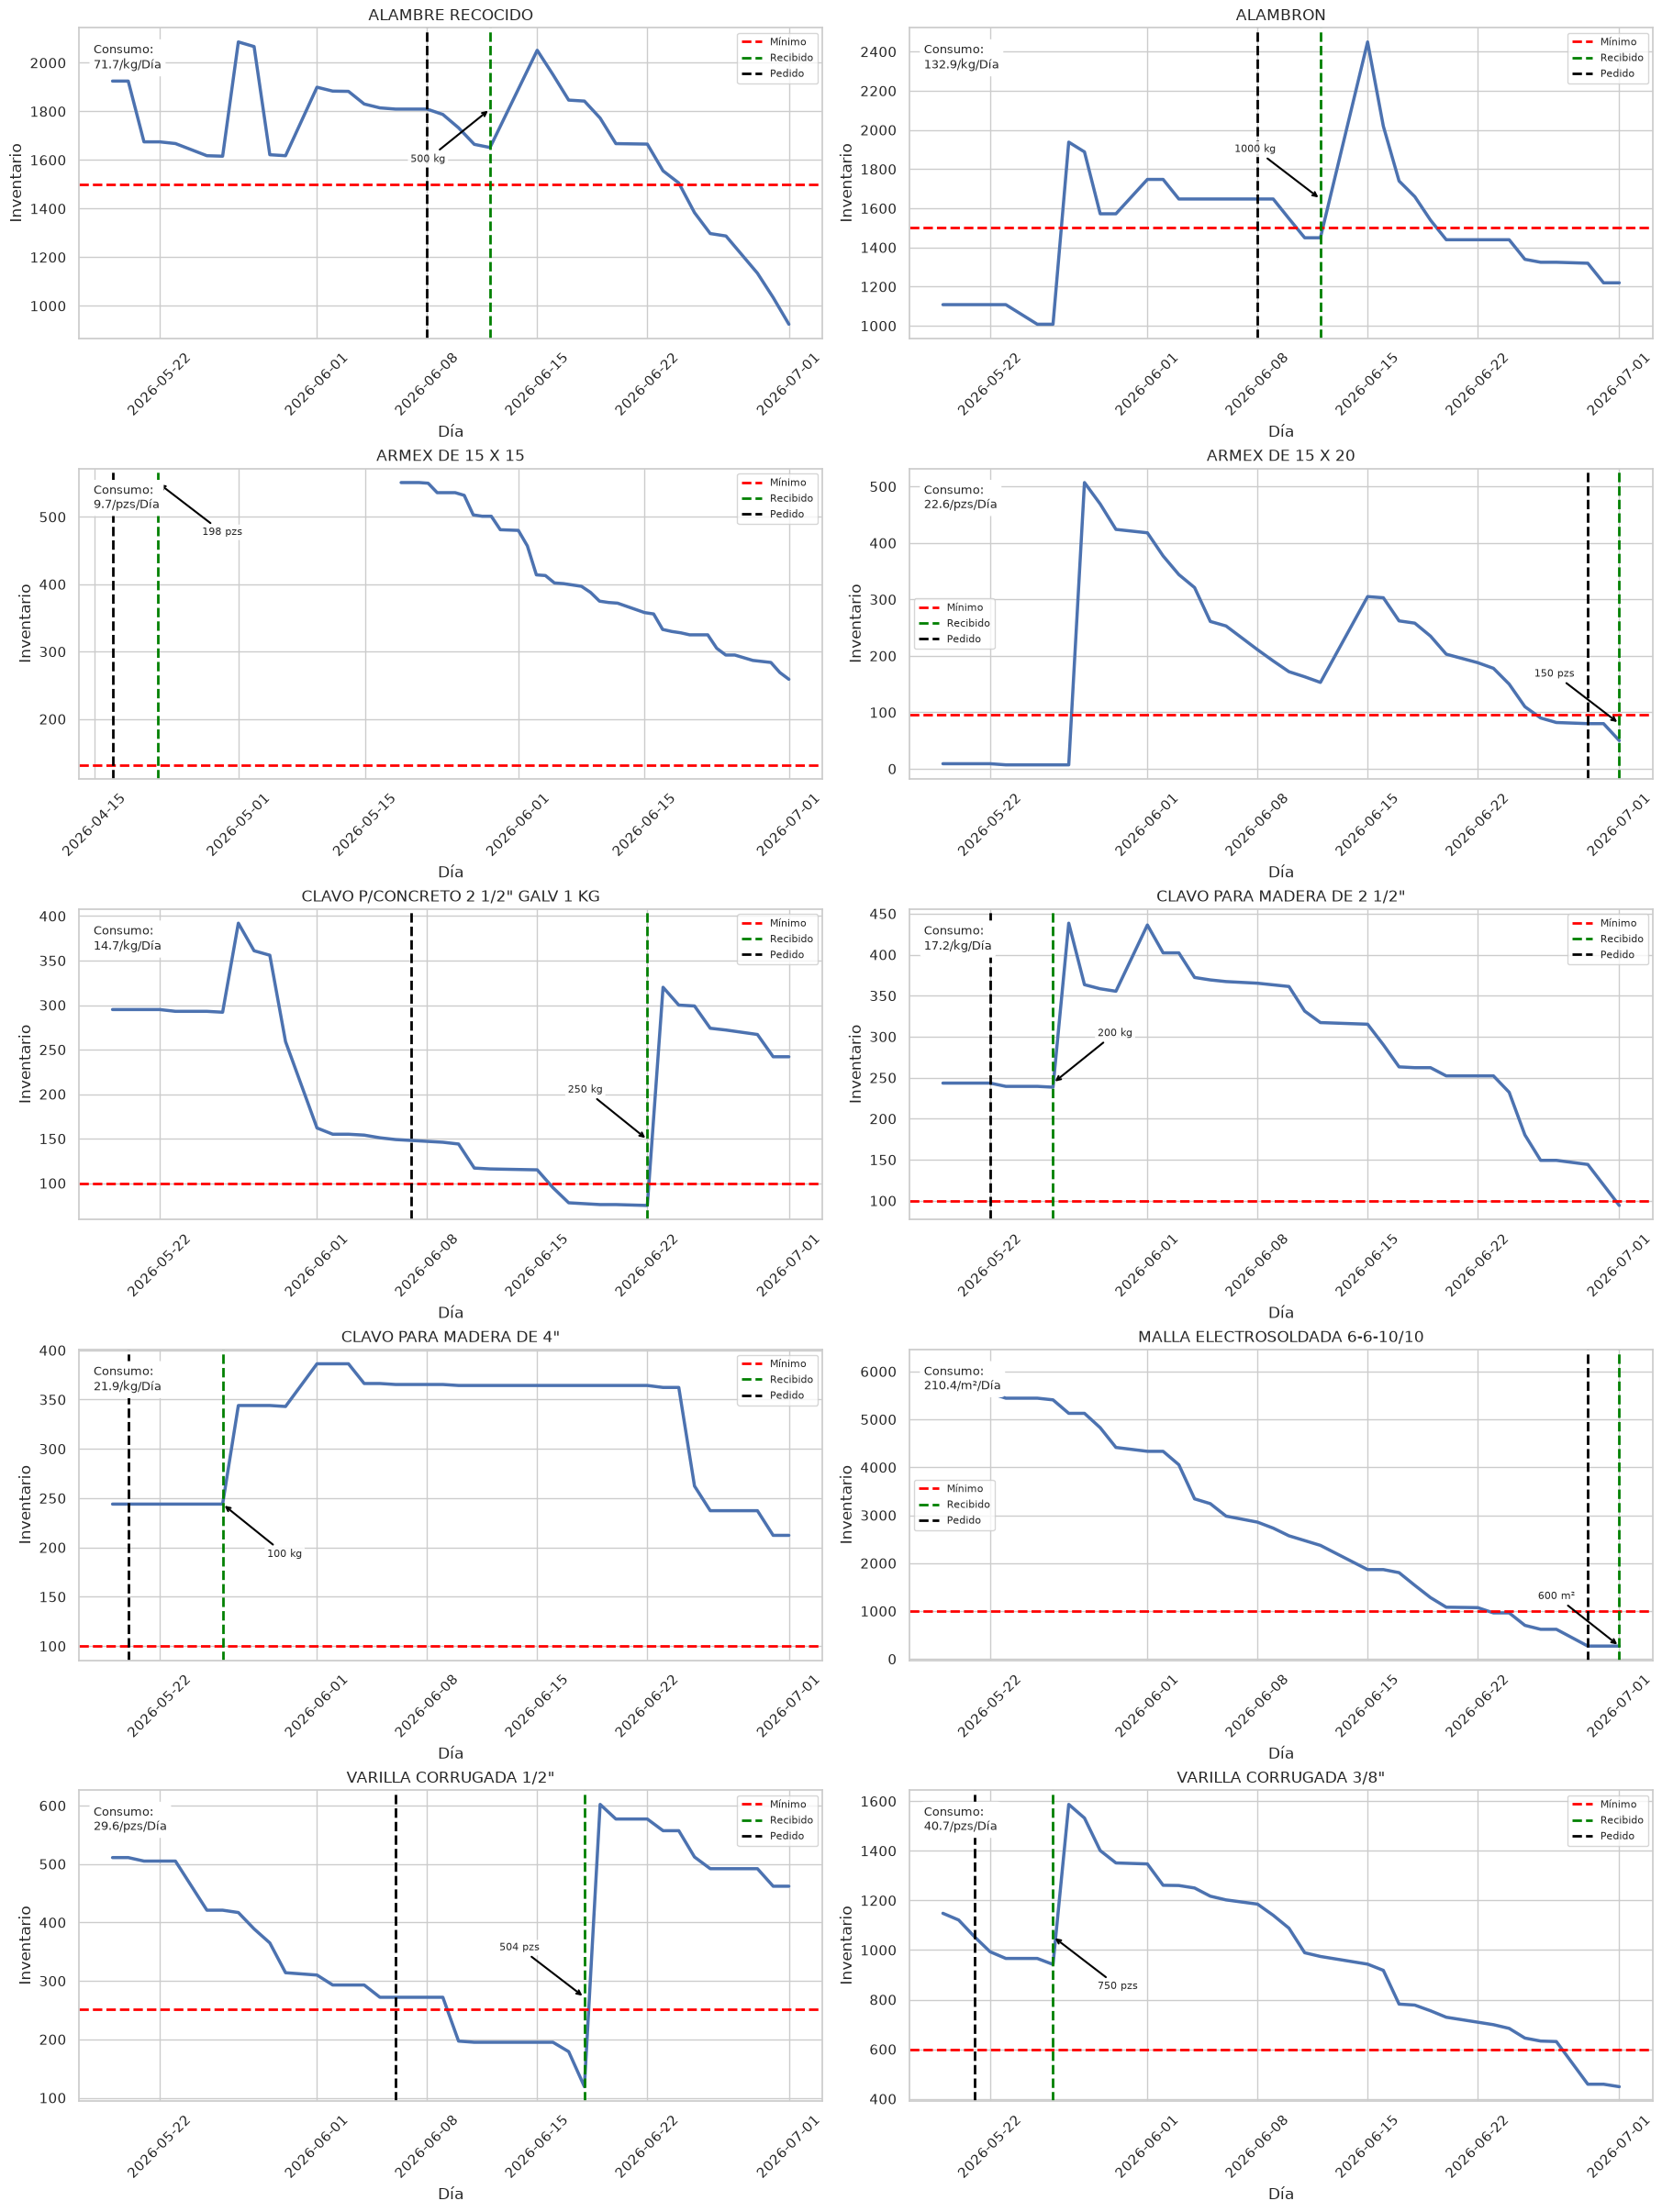

In [20]:
fig, axes = plt.subplots(5, 2, figsize=(18, 24), constrained_layout=True)

axes = axes.flatten()

for ax, (material, info) in zip(axes, mat_dict.items()):

    display_graphics(
        ax,
        material,
        info["purchase_date"],
        info["received"],
        info["quantity"],
        info["unit"],
        info["minimum_stock"]
    )

for ax in axes[len(mat_dict):]:
    ax.axis('offc')

fig.savefig(
    "/workspaces/steel_stock_management/pictures/inventario_aceros.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# SUPPLIERS

In [48]:
suppliers_df_raw = pd.read_csv('/workspaces/steel_stock_management/data/pedidos_proveedores.csv')
suppliers_df_raw.sample(5)

,Material,Proveedor (Texto),ID de pedido de compra,PU Promedio,Cantidad,Valor facturado,pedido,recibido,dias en llegar
50,"CLAVO PARA MADERA DE 4""",HOME DEPOT MEXICO S DE RL DE CV,44797,22.31,100.0,2231,20/05/2026,26/05/2026,6
31,MALLA ELECTROSOLDADA 6-6-10/10,HOME DEPOT MEXICO S DE RL DE CV,44294,21.20,1500.0,31800,05/05/2026,12/05/2026,7
3,ARMEX DE 15 x 15,MEXLAM CONCEPTOS SA DE CV,43483,117.00,396.0,46332,09/04/2026,15/04/2026,6
0,ARMEX DE 15 x 15,HOME DEPOT MEXICO S DE RL DE CV,40990,118.00,198.0,23364,06/01/2026,09/01/2026,3
21,ALAMBRON,HOME DEPOT MEXICO S DE RL DE CV,40990,16.00,1000.0,16000,07/01/2026,09/01/2026,2


In [49]:
suppliers_df_raw.columns= ['material', 
                        'proveedor', 
                        'id', 
                        'pu', 
                        'cantidad', 
                        'total', 
                        'pedido', 
                        'recibido', 
                        'espera']

suppliers_df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 66 entries, 0 to 65
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   material   66 non-null     str    
 1   proveedor  66 non-null     str    
 2   id         66 non-null     int64  
 3   pu         66 non-null     float64
 4   cantidad   66 non-null     float64
 5   total      66 non-null     int64  
 6   pedido     66 non-null     str    
 7   recibido   66 non-null     str    
 8   espera     66 non-null     int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 4.8 KB


In [59]:
suppliers_df_baking = suppliers_df_raw.copy()


suppliers_df_baking['material'] = suppliers_df_baking['material'].astype('category')
suppliers_df_baking['proveedor'] = suppliers_df_baking['proveedor'].astype('category')
suppliers_df_baking['pedido'] = pd.to_datetime(suppliers_df_baking['pedido'], format="%d/%m/%Y")
suppliers_df_baking['recibido'] = pd.to_datetime(suppliers_df_baking['recibido'], format="%d/%m/%Y")

suppliers_df_baking = suppliers_df_baking.drop(columns='id')

suppliers_df_baking['proveedor'] = suppliers_df_baking['proveedor'].map({
    'HOME DEPOT MEXICO S DE RL DE CV': 'HOME DEPOT',
    'MEXLAM CONCEPTOS SA DE CV': 'MEXLAM',
    'CEMEX': 'CEMEX',
    'ACEROS VIMAR MEXICO SAPI DE CV': 'VIMAR'
})

suppliers_df_baking.head()


,material,proveedor,pu,cantidad,total,pedido,recibido,espera
0,ARMEX DE 15 x 15,HOME DEPOT,118.00,198.0,23364,2026-01-06,2026-01-09,3
1,ARMEX DE 15 x 15,HOME DEPOT,136.14,144.0,19604,2026-01-22,2026-03-10,47
2,ARMEX DE 15 x 15,HOME DEPOT,141.81,396.0,56157,2026-02-16,2026-03-10,22
3,ARMEX DE 15 x 15,MEXLAM,117.00,396.0,46332,2026-04-09,2026-04-15,6
4,ARMEX DE 15 x 15,MEXLAM,117.00,198.0,23166,2026-04-17,2026-04-24,7


In [60]:
sup_df = suppliers_df_baking.copy()

sup_df.sample(10)

,material,proveedor,pu,cantidad,total,pedido,recibido,espera
10,ARMEX DE 15 x 20,MEXLAM,117.00,321.0,37557,2026-04-09,2026-04-15,6
37,"CLAVO P/CONCRETO 2 1/2"" GALV 1 KG",HOME DEPOT,50.04,100.0,5004,2026-05-05,2026-05-12,7
61,"VARILLA CORRUGADA 3/8""",HOME DEPOT,125.51,1200.0,150612,2026-05-05,2026-05-12,7
56,"VARILLA CORRUGADA 1/2""",MEXLAM,216.67,504.0,109202,2026-04-17,2026-04-24,7
9,ARMEX DE 15 x 20,HOME DEPOT,144.24,240.0,34618,2026-02-16,2026-02-28,12
12,ALAMBRE RECOCIDO,VIMAR,24.50,500.0,12250,2026-06-08,2026-06-12,4
14,ALAMBRE RECOCIDO,HOME DEPOT,19.85,1000.0,19850,2026-01-22,2026-03-10,47
19,ALAMBRE RECOCIDO,MEXLAM,20.30,1500.0,30450,2026-04-17,2026-04-24,7
24,ALAMBRON,HOME DEPOT,16.91,1000.0,16910,2026-03-26,2026-04-02,7
27,MALLA ELECTROSOLDADA 6-6-10/10,HOME DEPOT,14.96,2500.0,37400,2026-01-22,2026-02-13,22


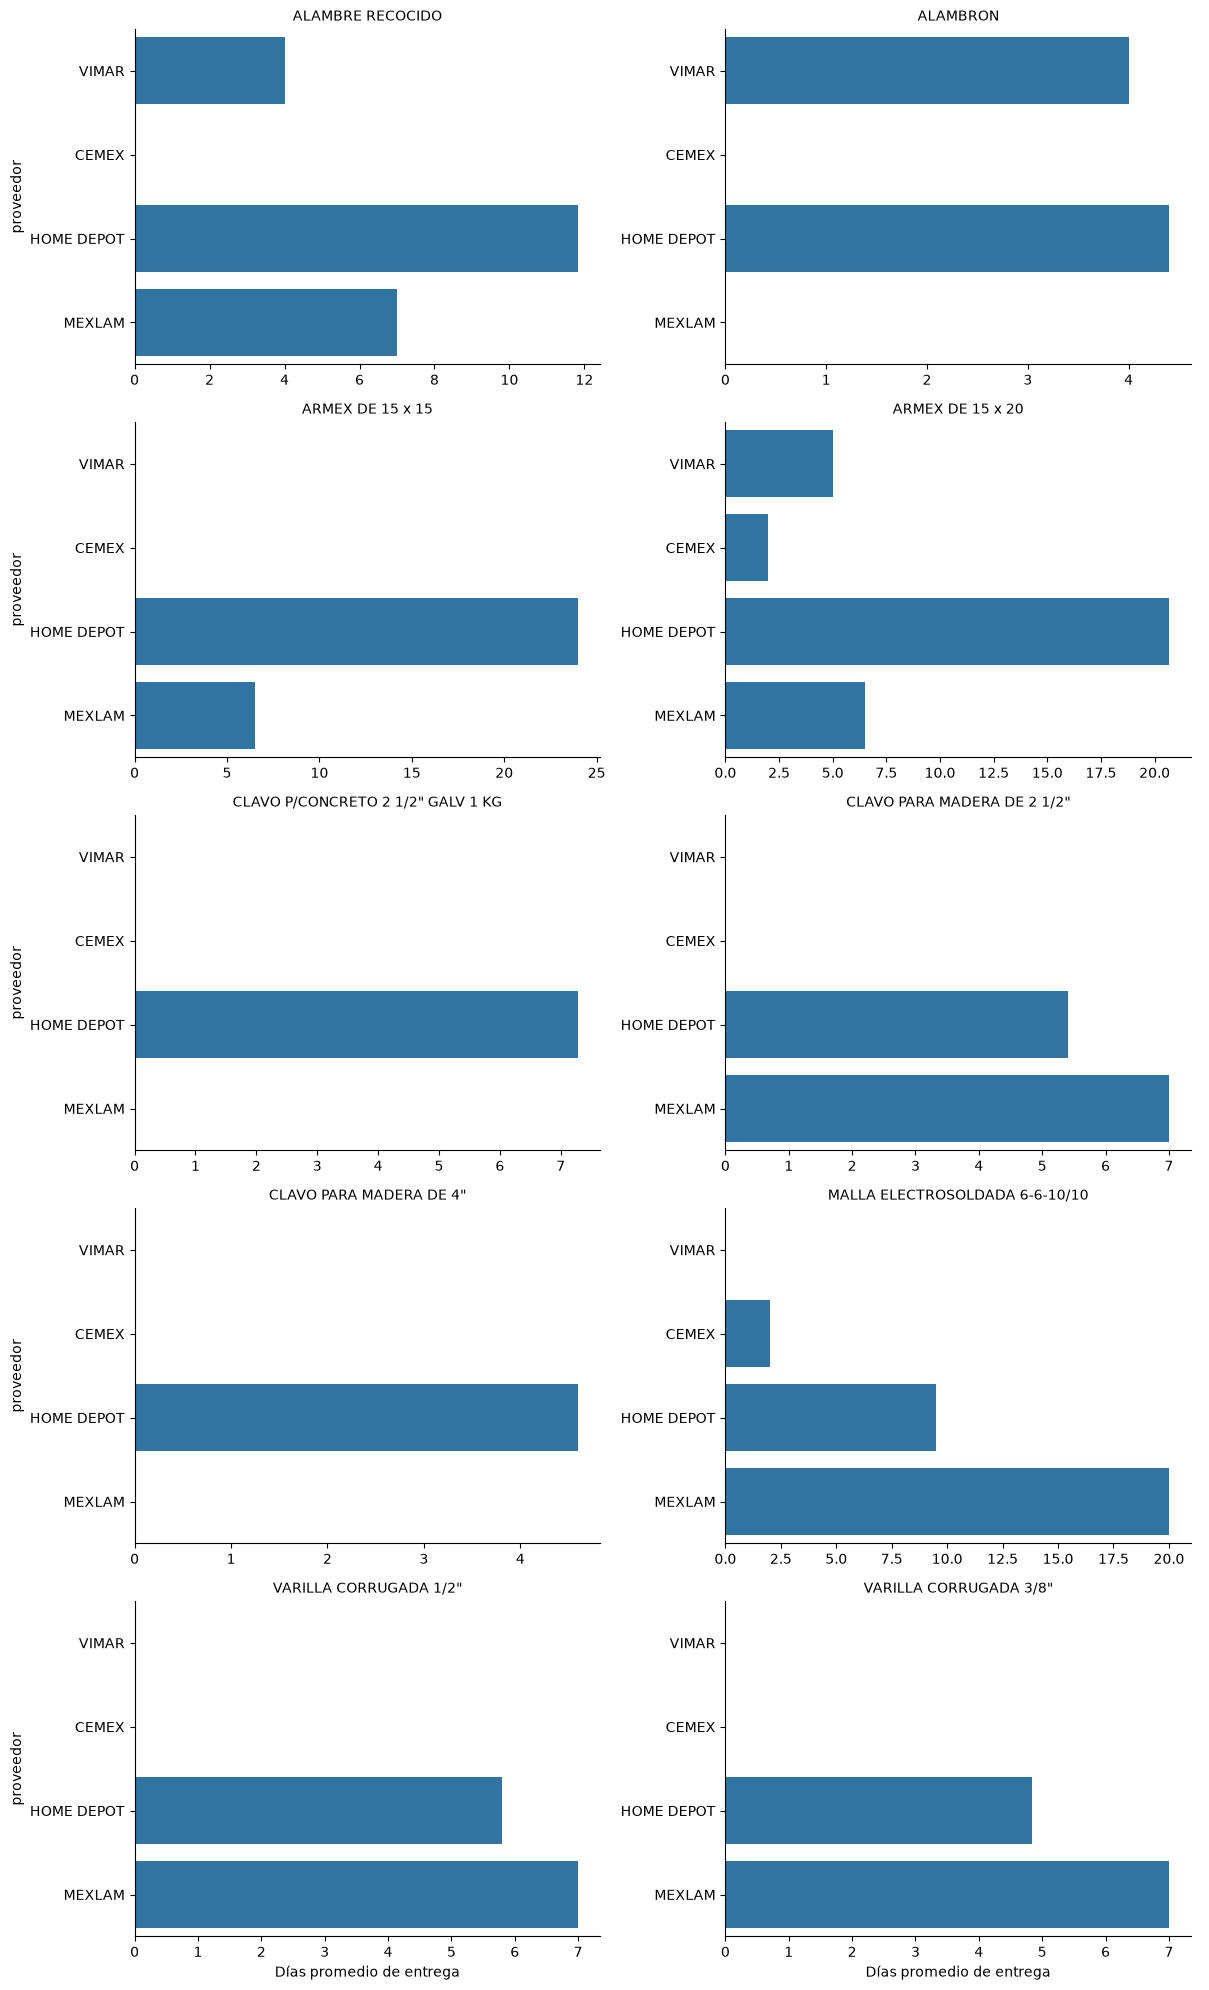

In [61]:
supplier_summary = (
    sup_df
    .groupby(["material", "proveedor"])
    .agg(
        avg_lead=("espera", "mean"),
        std_lead=("espera", "std"),
        purchases=("espera", "count")
    )
    .reset_index()
)

g = sns.catplot(
    data=supplier_summary,
    x="avg_lead",
    y="proveedor",
    col="material",
    kind="bar",
    col_wrap=2,
    height=4,
    aspect=1.5,
    sharex=False,
    sharey=False
)

g.set_axis_labels('Días promedio de entrega')
g.set_titles('{col_name}')

plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'TIEMPO PROMEDIO DE ENTREGA POR MATERIAL Y PROVEEDOR')

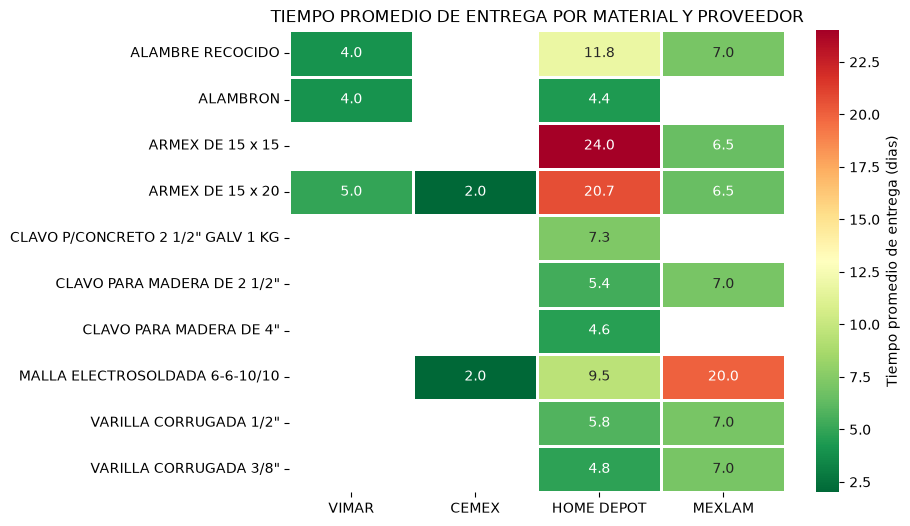

In [69]:
pivot = supplier_summary.pivot(
    index="material",
    columns="proveedor",
    values="avg_lead"
)

plt.figure(figsize=(8,6))

sns.heatmap(
    pivot,
    annot=True,
    fmt=".1f",
    cmap="RdYlGn_r",
    linewidths=1,
    cbar_kws={"label":"Tiempo promedio de entrega (dias)"}
)

plt.xlabel("")
plt.ylabel("")
plt.title("TIEMPO PROMEDIO DE ENTREGA POR MATERIAL Y PROVEEDOR")

In [75]:
supplier_table = (
    sup_df
    .groupby(["material", "proveedor"])
    .agg(
        promedio=("espera", "mean"),
        std=("espera", "std"),
        min=("espera", "min"),
        max=("espera", "max"),
        precio_promedio=("pu", "mean"),
        compras=("pedido", "count"),
        subtotal=("total", "sum"),
        promedio_cantidad=("cantidad", "mean")
    )
    .reset_index()
)

supplier_table["cv"] = (
    supplier_table["std"] / supplier_table["promedio"]
)

supplier_table["cv"] = supplier_table["cv"].fillna(0)

supplier_table = supplier_table.sort_values(
    ["material", "promedio"]
)

supplier_table.head(10)

,material,proveedor,promedio,std,min,max,precio_promedio,compras,subtotal,promedio_cantidad,cv
0,ALAMBRE RECOCIDO,VIMAR,4.000000,NaN,4,4,24.500000,1,12250,500.000000,0.000000
2,ALAMBRE RECOCIDO,MEXLAM,7.000000,NaN,7,7,20.300000,1,30450,1500.000000,0.000000
1,ALAMBRE RECOCIDO,HOME DEPOT,11.833333,17.348391,2,47,21.308333,6,147275,1166.666667,1.466061
3,ALAMBRON,VIMAR,4.000000,NaN,4,4,18.300000,1,18300,1000.000000,0.000000
4,ALAMBRON,HOME DEPOT,4.400000,1.949359,2,7,17.410000,5,87050,1000.000000,0.443036
6,ARMEX DE 15 x 15,MEXLAM,6.500000,0.707107,6,7,117.000000,2,69498,297.000000,0.108786
5,ARMEX DE 15 x 15,HOME DEPOT,24.000000,22.068076,3,47,131.983333,3,99125,246.000000,0.919503
8,ARMEX DE 15 x 20,CEMEX,2.000000,NaN,2,2,139.400000,1,20910,150.000000,0.000000
7,ARMEX DE 15 x 20,VIMAR,5.000000,1.414214,4,6,130.000000,2,89960,346.000000,0.282843
10,ARMEX DE 15 x 20,MEXLAM,6.500000,0.707107,6,7,117.000000,2,54405,232.500000,0.108786


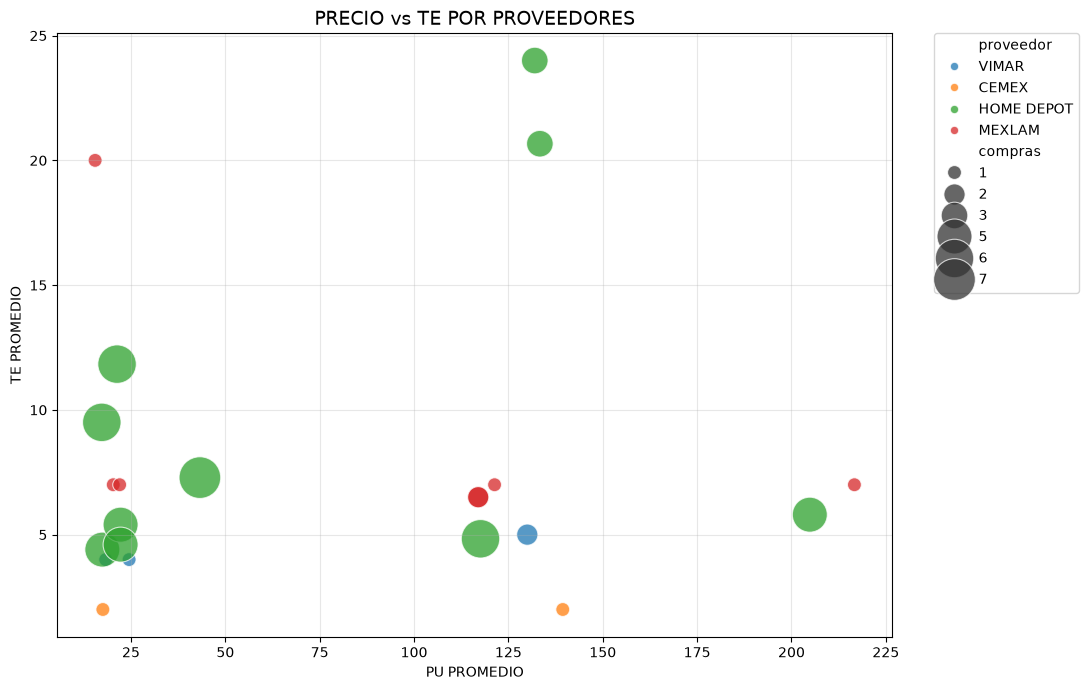

In [76]:
plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=supplier_table,
    x="precio_promedio",
    y="promedio",
    hue="proveedor",
    size="compras",
    sizes=(100, 900),
    alpha=0.75
)

plt.title("PRECIO vs TE POR PROVEEDORES", fontsize=14)
plt.xlabel("PU PROMEDIO")
plt.ylabel("TE PROMEDIO")
plt.grid(True, alpha=0.3)

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    borderaxespad=0
)

plt.tight_layout()
plt.show()

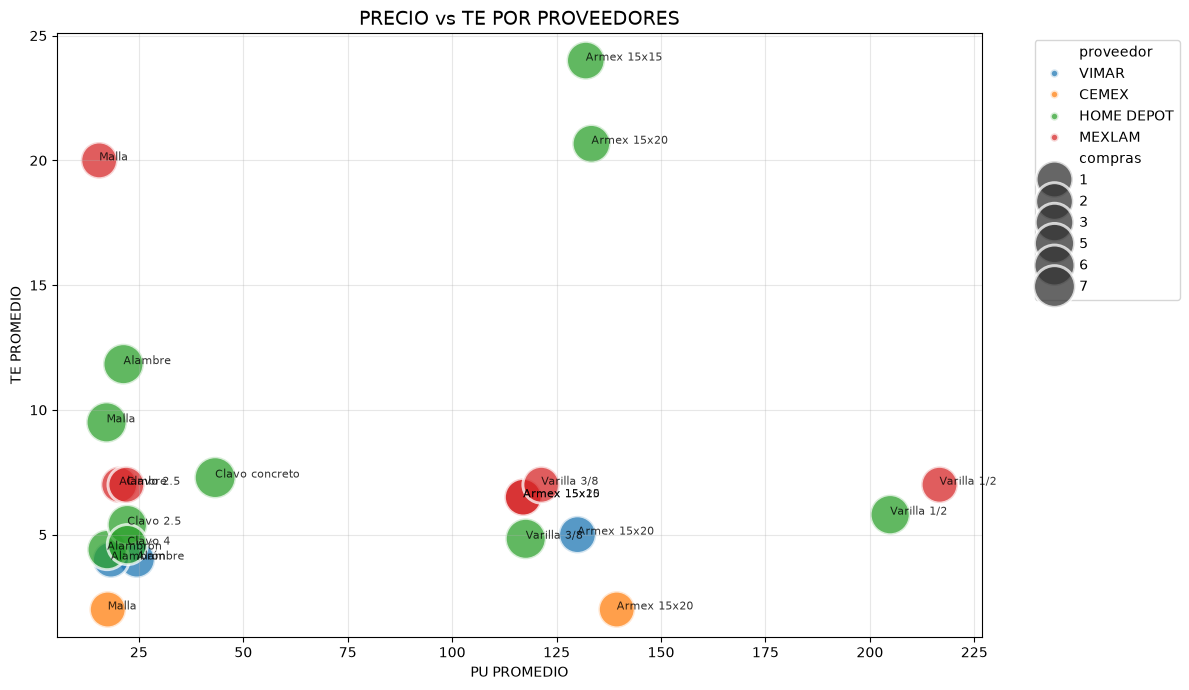

In [81]:
material_short = {
    "ALAMBRE RECOCIDO": "Alambre",
    "ALAMBRON": "Alambrón",
    "ARMEX DE 15 x 15": "Armex 15x15",
    "ARMEX DE 15 x 20": "Armex 15x20",
    "CLAVO P/CONCRETO 2 1/2\" GALV 1 KG": "Clavo concreto",
    "CLAVO PARA MADERA DE 2 1/2\"": "Clavo 2.5",
    "CLAVO PARA MADERA DE 4\"": "Clavo 4",
    "MALLA ELECTROSOLDADA 6-6-10/10": "Malla",
    "VARILLA CORRUGADA 1/2\"": "Varilla 1/2",
    "VARILLA CORRUGADA 3/8\"": "Varilla 3/8"
}

supplier_table["material_short"] = (
    supplier_table["material"].map(material_short)
    .fillna(supplier_table["material"])
)

plt.figure(figsize=(12, 7))

ax = sns.scatterplot(
    data=supplier_table,
    x="precio_promedio",
    y="promedio",
    hue="proveedor",
    size="compras",
    sizes=(700, 900),
    alpha=0.75
)

for _, row in supplier_table.iterrows():
    ax.text(
        row["precio_promedio"],
        row["promedio"],
        row["material_short"],
        fontsize=8,
        alpha=0.8
    )

plt.title('PRECIO vs TE POR PROVEEDORES', fontsize=14)
plt.xlabel("PU PROMEDIO")
plt.ylabel("TE PROMEDIO")
plt.grid(True, alpha=0.3)

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()